In [29]:
#problem 1
# import pandas 
import pandas as pd
# import numpy
import numpy as np
# import matplotlib
from matplotlib import pyplot as plt
# make plots appear and be stored within the notebook
%matplotlib inline

sig = pd.read_csv("Sig_Eqs.tsv",delimiter="\t")
sig.columns
# this windows is used to see the data




Index(['Search Parameters', 'Id', 'Year', 'Mo', 'Dy', 'Hr', 'Mn', 'Sec', 'Tsu',
       'Vol', 'Country', 'Area', 'Region', 'Location Name', 'Latitude',
       'Longitude', 'Focal Depth (km)', 'Mag', 'Mw', 'Ms', 'Mb', 'Ml', 'Mfa',
       'Unk', 'MMI Int', 'Deaths', 'Death Description', 'Missing',
       'Missing Description', 'Injuries', 'Injuries Description',
       'Damage ($Mil)', 'Damage Description', 'Houses Destroyed',
       'Houses Destroyed Description', 'Houses Damaged',
       'Houses Damaged Description', 'Total Deaths', 'Total Death Description',
       'Total Missing', 'Total Missing Description', 'Total Injuries',
       'Total Injuries Description', 'Total Damage ($Mil)',
       'Total Damage Description', 'Total Houses Destroyed',
       'Total Houses Destroyed Description', 'Total Houses Damaged',
       'Total Houses Damaged Description'],
      dtype='str')

In [32]:
#problem 1.1
fenzu=sig.groupby(['Country'])
jiahe=fenzu['Deaths'].sum()
jiahe.sort_values(ascending=False).head(20)

Country
CHINA           2139225.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
HAITI            323484.0
AZERBAIJAN       319251.0
SYRIA            289826.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64

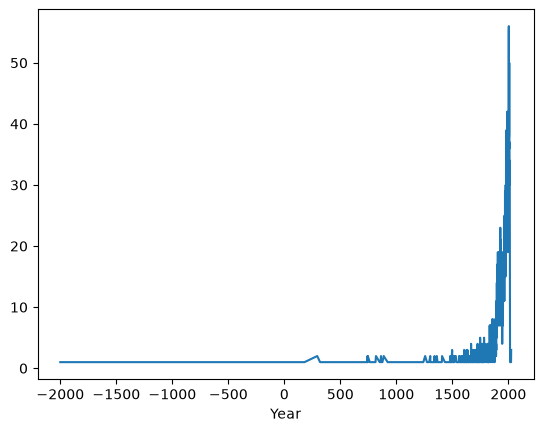

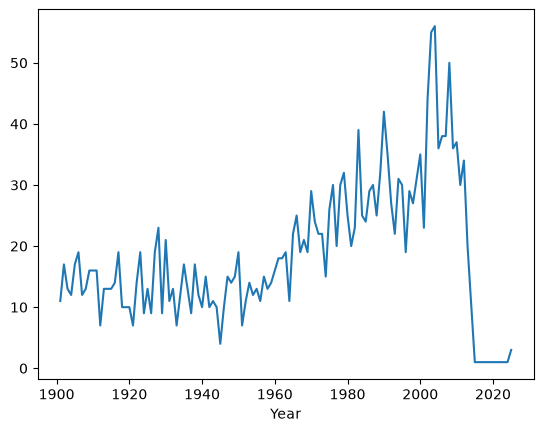

In [44]:
#problem 1.2
zhenji=sig.loc[(sig['Ms'] > 3)]
huitu=zhenji.groupby("Year").size()
huitu.plot(x="Year",y="Number")
plt.show()
huitu=huitu.loc[huitu.index>1900]
huitu.plot()
plt.show()

In [66]:
#problem 1.3
def CountEq_LargestEq(country):
    guojia=sig.loc[sig["Country"]==country]
    cisu=len(guojia)
    guojia=guojia.sort_values("Ms",ascending=False)
    zuida=guojia.iloc[0]
    return cisu,zuida["Year"],zuida["Mo"],zuida["Dy"],zuida["Location Name"]
CountEq_LargestEq("CHINA")
fenzu=sig.groupby("Country").size()
jieguo=pd.DataFrame(columns=["Number","Year","Mo","Dy","Location Name"])
for country in fenzu.index:
    jieguo.loc[country]=CountEq_LargestEq(country)
jieguo=jieguo.sort_values("Number",ascending=False)
jieguo


,Number,Year,Mo,Dy,Location Name
CHINA,627,1920.0,12.0,16.0,"CHINA: GANSU PROVINCE, SHANXI PROVINCE"
JAPAN,429,869.0,7.0,13.0,JAPAN: SANRIKU
INDONESIA,427,2004.0,12.0,26.0,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
IRAN,385,856.0,12.0,22.0,"IRAN: DAMGHAN, QUMIS"
TURKEY,359,1999.0,8.0,17.0,"TURKEY: ISTANBUL, KOCAELI, SAKARYA"
...,...,...,...,...,...
SRI LANKA,1,1882.0,1.0,NaN,SRI LANKA: TRINCOMALEE
TASMAN SEA,1,1892.0,1.0,26.0,TASMAN SEA
SUDAN,1,1993.0,8.0,1.0,SUDAN: KHARTOUM
WALLIS AND FUTUNA (FRENCH TERRITORY),1,1993.0,3.0,12.0,FUTUNA ISLAND


C:\Users\Administrator\AppData\Local\Temp\ipykernel_8912\3311314051.py:2: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  baoan=pd.read_csv("Baoan_Weather_1998_2022.csv")


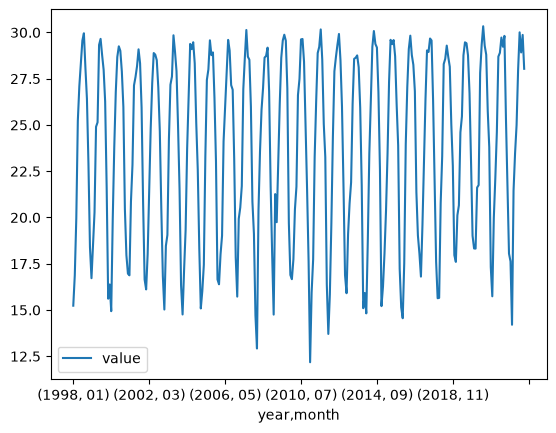

In [95]:
#problem 2
baoan=pd.read_csv("Baoan_Weather_1998_2022.csv")
baoan[['value','quantity']]=baoan['TMP'].str.split(',',expand=True)
baoan['value']=pd.to_numeric(baoan['value'])
baoan['quantity']=pd.to_numeric(baoan['quantity'])
baoan=baoan.loc[((baoan['quantity']==1) | (baoan['quantity']==5))]
baoan['value']=baoan['value']/10
baoan[['year','month','day_time']]=baoan['DATE'].str.split('-',expand=True)
Monthly_T=baoan[['year','month','value']].groupby(['year','month']).mean().plot()
plt.show()

In [115]:
#problem 3
df = pd.read_csv(
    'ibtracs.ALL.list.v04r00.csv',
    usecols=range(17),
    skiprows=[1],
    parse_dates=['ISO_TIME'],
    keep_default_na=False,
    na_values=['NOT_NAMED', ''],
    skipinitialspace=True,
    low_memory=False
)

df.head()


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.9000,80.3000,NaN,NaN,NaN,main,43,0.0,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,NaN,NaN,NaN,main,0,0.0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,NaN,NaN,NaN,main,0,0.0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,NaN,NaN,NaN,main,0,0.0,__________P___
4,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,NaN,NaN,NaN,main,0,0.0,__________O___


In [106]:
#problem 3.1
df['WMO_WIND'] = pd.to_numeric(df['WMO_WIND'])
Storms = df.groupby('SID').agg({'NAME': 'first','WMO_WIND': 'max'})
Storms = Storms.sort_values('WMO_WIND', ascending=False)
Storms.head(10)





,NAME,WMO_WIND
SID,,
2015293N13266,PATRICIA,185.0
1980214N11330,ALLEN,165.0
2005289N18282,WILMA,160.0
1997253N12255,LINDA,160.0
1988253N12306,GILBERT,160.0
1935241N23291,NaN,160.0
2019236N10314,DORIAN,160.0
2009288N07267,RICK,155.0
1998295N12284,MITCH,155.0


In [107]:
#problem 3.2
Storms.head(20)



,NAME,WMO_WIND
SID,,
2015293N13266,PATRICIA,185.0
1980214N11330,ALLEN,165.0
2005289N18282,WILMA,160.0
1997253N12255,LINDA,160.0
1988253N12306,GILBERT,160.0
1935241N23291,NaN,160.0
2019236N10314,DORIAN,160.0
2009288N07267,RICK,155.0
1998295N12284,MITCH,155.0


In [109]:
#problem 3.3
ques3 = df.groupby('BASIN').size()
ques3 = ques3.sort_values(ascending=False)
ques3


BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
dtype: int64

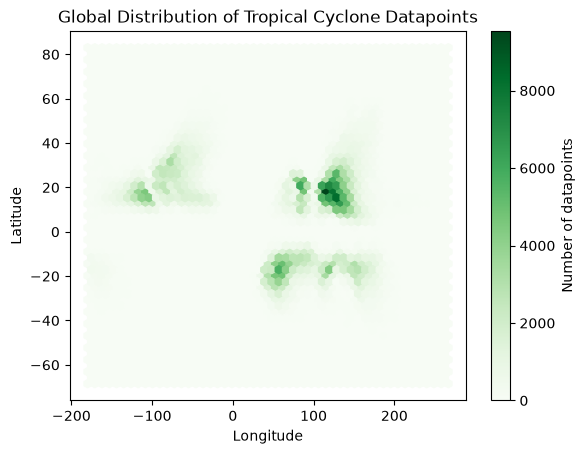

In [110]:
#problem 3.4
x = df['LON']
y = df['LAT']

plt.hexbin(x, y, gridsize=50, cmap='Greens')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Global Distribution of Tropical Cyclone Datapoints')
plt.colorbar(label='Number of datapoints')

plt.show()

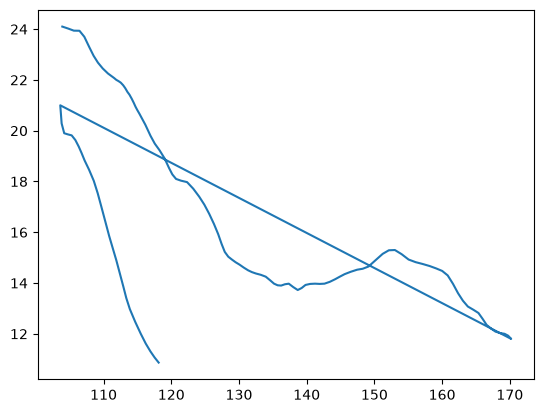

In [114]:
# problem3.5
Mangkhut = df.loc[(df['NAME'] == 'MANGKHUT')]
Mangkhut = Mangkhut.sort_values('ISO_TIME')
plt.plot(Mangkhut['LON'],Mangkhut['LAT'])
plt.show()

In [120]:
# problem 3.6
ques6=df.loc[(df['SEASON']>=1970)&((df['BASIN']=='WP')|(df['BASIN']=='EP'))]
ques6


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,NaN,1006.0,tokyo,main,1088,1088.0,_OO___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,NaN,NaN,NaN,main,1109,1109.0,_PP___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,NaN,1002.0,tokyo,main,1143,1143.0,_OO___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,NaN,NaN,NaN,main,1171,1168.0,_PP___________
350398,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,NaN,998.0,tokyo,main,1182,1179.0,_OO___________
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
707085,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 15:00:00,TS,13.99570,-90.294,NaN,NaN,NaN,PROVISIONAL,0,0.0,P_____________
707086,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 18:00:00,NR,14.50000,-91.000,NaN,NaN,NaN,PROVISIONAL,0,NaN,O_____________
707174,2022286N15151,2022,80,WP,MM,NaN,2022-10-12 12:00:00,NR,15.20000,151.300,NaN,NaN,NaN,PROVISIONAL,1985,1974.0,O_____________
707175,2022286N15151,2022,80,WP,MM,NaN,2022-10-12 15:00:00,NR,15.05000,151.325,NaN,NaN,NaN,PROVISIONAL,1974,1952.0,P_____________


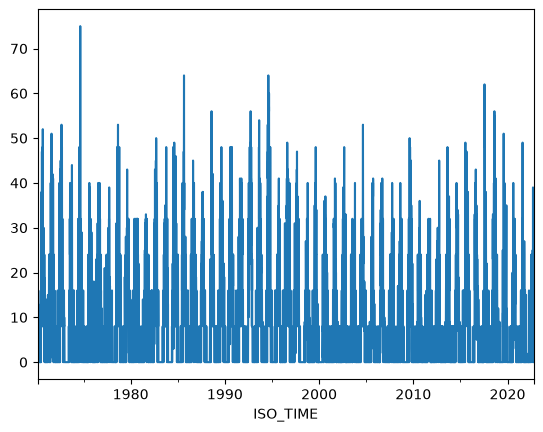

In [126]:
# problem 3.7
Daily_count = ques6.set_index('ISO_TIME').resample('D').size()
Daily_count.plot()
plt.show()

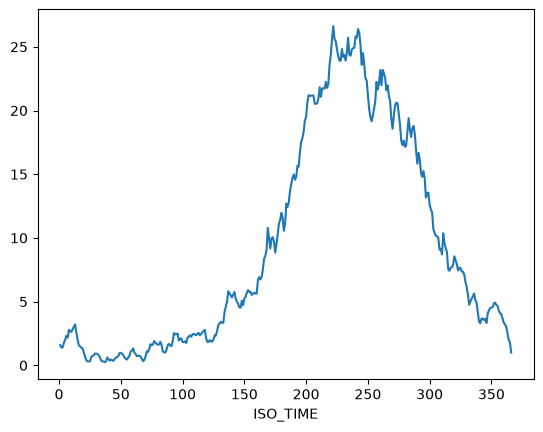

In [127]:
# problem 3.8
Climatology = Daily_count.groupby(Daily_count.index.dayofyear).mean()
Climatology.plot()
plt.show()

In [130]:
# problem 3.9
Daily_data = Daily_count.to_frame(name='count')
Daily_data['day_of_year'] = Daily_data.index.dayofyear
Daily_data['climatology'] = Daily_data['day_of_year'].map(Climatology)
Daily_data['anomaly'] = (Daily_data['count'] - Daily_data['climatology'])
Daily_data.head()

,count,day_of_year,climatology,anomaly
ISO_TIME,,,,
1970-02-19,8,50,0.981132,7.018868
1970-02-20,8,51,0.905660,7.094340
1970-02-21,8,52,0.811321,7.188679
1970-02-22,8,53,0.622642,7.377358
1970-02-23,8,54,0.509434,7.490566


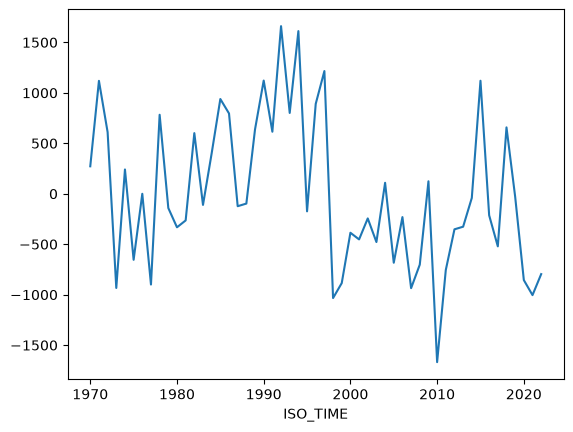

In [132]:
# problem 3.10
# problem 3.10
Annual_anomaly = Daily_data['anomaly'].resample('YE').sum()
Annual_anomaly.index = Annual_anomaly.index.year
Annual_anomaly.plot()
plt.show()

In [144]:
# problrm 4.1
import pandas as pd
import matplotlib.pyplot as plt

qiwen = pd.read_csv('global_temperature_anomaly_annual.csv', skiprows=3)
qiwen.columns = ['nian', 'piancha']
qiwen['nian'] = pd.to_numeric(qiwen['nian'], errors='coerce')
qiwen['piancha'] = pd.to_numeric(qiwen['piancha'], errors='coerce')
qiwen = qiwen.dropna().drop_duplicates()

<Axes: xlabel='nian'>

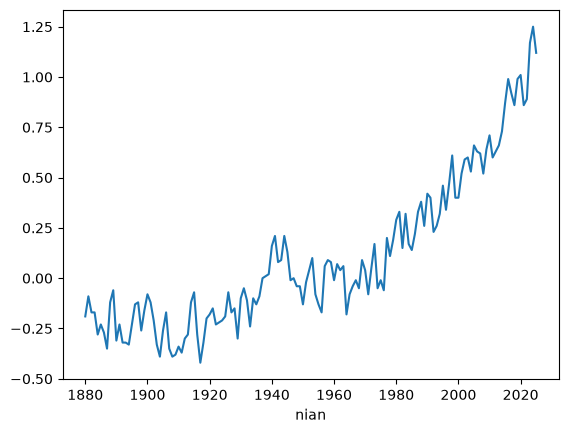

In [149]:
# problrm 4.2
qiwen.plot(x='nian', y='piancha', legend=False)
plt.show()

In [147]:
# problrm 4.3
qiwen.describe()

,nian,piancha
count,146.000000,146.000000
mean,1952.500000,0.103904
std,42.290661,0.381415
min,1880.000000,-0.420000
25%,1916.250000,-0.170000
50%,1952.500000,-0.010000
75%,1988.750000,0.320000
max,2025.000000,1.250000
